# Proyecto final · Hitos 1 y 2: ¿con qué nivel de retraso llegará una entrega de última milla?

**Grupo 14 · Joaquín Rivas · Matías Ortega** · Machine Learning Supervisado (UDD)

**Datos:** *Amazon Delivery Dataset* (Kaggle, 43.739 entregas). Variable objetivo: `nivel_retraso`, 5 clases construidas a partir del tiempo de entrega.

**Esquema de trabajo** (el mismo del notebook de clases `MLP_Transformer_TabPFN_HR.ipynb`, adaptado a multiclase):

| Parte | Qué hacemos |
|---|---|
| 1 | Contexto de los datos |
| 2 | Carga y exploración: tipos, faltantes, duplicados y errores |
| 3 | Variable objetivo multiclase y su balance |
| 4 | Matrices X, y y partición estratificada |
| 5 | Preprocesado dentro del pipeline |
| **A** | **Red MLP** (`MLPClassifier`): base y ajustada con `RandomizedSearchCV` |
| **B** | **TabPFN**: base y ajustado con `GridSearchCV` |
| **C** | Comparación final de los cuatro modelos (F1 macro y tiempos) |
| **D** | Conclusiones del Hito 1 |
| **E** | Plan de acción priorizado: ranking, curva de ganancia, lift, ROI y sensibilidad (Hito 2) |
| **F** | Ventana de operación para el simulador what-if (Hito 2) |
| **G** | Conclusiones del Hito 2 |

## 1. Contexto de los datos

| Pregunta | Respuesta |
|---|---|
| **Industria y proceso** | Comercio electrónico, **logística de última milla**: el tramo entre la tienda o centro de distribución y la casa del cliente. Es el tramo más caro de la cadena y el que más pesa en la experiencia del cliente. |
| **Fuente** | *Amazon Delivery Dataset*, Sujal Suthar, Kaggle (2024), licencia MIT: https://www.kaggle.com/datasets/sujalsuthar/amazon-delivery-dataset. Entregas de 2022 (11 de febrero a 6 de abril) en ciudades de la India. La página no indica la fuente original: lo tratamos como datos de una operación tipo marketplace, no como cifras oficiales de Amazon. |
| **Qué es cada fila** | Un pedido entregado: quién lo repartió, desde dónde y hacia dónde, cuándo se pidió y retiró, en qué condiciones de clima y tráfico, en qué vehículo y cuánto demoró. |
| **Qué predecimos** | El **nivel de retraso** de la entrega, en 5 clases (sección 3), a partir de lo que se sabe **cuando se retira el pedido**. |
| **Para qué le sirve a la empresa** | Avisar antes al cliente, reasignar repartidores o vehículos, priorizar los pedidos con riesgo de **retraso crítico** y planificar la dotación por zona y horario. En el Hito 2 esto se convierte en un simulador y un plan priorizado. |

**Variables principales**

| Variable | Tipo | Significado |
|---|---|---|
| `Agent_Age` | Numérica | Edad del repartidor (años) |
| `Agent_Rating` | Numérica | Calificación del repartidor (1 a 5) |
| `Store_Latitude`, `Store_Longitude`, `Drop_Latitude`, `Drop_Longitude` | Numéricas | Coordenadas de la tienda y del cliente: con ellas calculamos la **distancia en km** |
| `Order_Date`, `Order_Time`, `Pickup_Time` | Fecha y horas | Día y hora del pedido y del retiro: de aquí salen el **día de la semana**, la **hora del pedido** y la **espera hasta el retiro** |
| `Weather` | Nominal (6) | Clima: Sunny, Cloudy, Fog, Windy, Stormy, Sandstorms |
| `Traffic` | Ordinal (4) | Tráfico: Low < Medium < High < Jam (atasco) |
| `Vehicle` | Nominal (4) | motorcycle, scooter, van, bicycle |
| `Area` | Nominal (4) | Tipo de zona: Metropolitian, Urban, Semi-Urban, Other |
| `Category` | Nominal (16) | Categoría del producto (Electronics, Grocery, Books, …) |
| `Delivery_Time` | Numérica | Minutos desde el pedido hasta la entrega. **Define la clase**: no entra como predictora |

## 2. Carga y exploración

In [1]:
# librerias necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from time import time
import joblib
# Filtrar warning
import warnings
warnings.filterwarnings('ignore')
# Estilo de grafico
plt.style.use('ggplot')
# reproductibilidad
semilla=2026
np.random.seed(semilla)

In [2]:
# Leer los datos (Colab: desde Drive; local: carpeta datos del proyecto)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ruta="/content/drive/MyDrive/Data_set/amazon_delivery.csv"
except ImportError:
    ruta="datos/amazon_delivery.csv"
df=pd.read_csv(ruta)
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (43739, 16)


,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys


In [3]:
# Tipos de variables
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 43739 entries, 0 to 43738
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         43739 non-null  str    
 1   Agent_Age        43739 non-null  int64  
 2   Agent_Rating     43685 non-null  float64
 3   Store_Latitude   43739 non-null  float64
 4   Store_Longitude  43739 non-null  float64
 5   Drop_Latitude    43739 non-null  float64
 6   Drop_Longitude   43739 non-null  float64
 7   Order_Date       43739 non-null  str    
 8   Order_Time       43739 non-null  str    
 9   Pickup_Time      43739 non-null  str    
 10  Weather          43648 non-null  str    
 11  Traffic          43739 non-null  str    
 12  Vehicle          43739 non-null  str    
 13  Area             43739 non-null  str    
 14  Delivery_Time    43739 non-null  int64  
 15  Category         43739 non-null  str    
dtypes: float64(5), int64(2), str(9)
memory usage: 8.6 MB


In [4]:
# Existen datos ausentes
df.isna().sum()   # Agent_Rating (54) y Weather (91) -> se imputan en el preprocesado

Order_ID            0
Agent_Age           0
Agent_Rating       54
Store_Latitude      0
Store_Longitude     0
Drop_Latitude       0
Drop_Longitude      0
Order_Date          0
Order_Time          0
Pickup_Time         0
Weather            91
Traffic             0
Vehicle             0
Area                0
Delivery_Time       0
Category            0
dtype: int64

In [5]:
# Ojo: hay faltantes escritos como texto "NaN " y categorias con espacios al final
print(df["Traffic"].value_counts().to_dict())
print("Order_Time con texto 'NaN':", (df["Order_Time"].str.strip()=="NaN").sum())
print("Son las mismas filas que Weather faltante:", ((df["Order_Time"].str.strip()=="NaN") & df["Weather"].isna()).sum())

{'Low ': 14999, 'Jam ': 13725, 'Medium ': 10628, 'High ': 4296, 'NaN ': 91}
Order_Time con texto 'NaN': 91
Son las mismas filas que Weather faltante: 91


**Hallazgo:** `Traffic`, `Vehicle` y `Area` traen un espacio al final (`"High "`), y `Traffic` y `Order_Time` tienen el faltante escrito como el texto `"NaN"`. Son las mismas 91 filas en que falta `Weather`. No limpiamos el DataFrame a mano: el primer paso del pipeline quita los espacios y convierte ese texto en un faltante real, que luego se imputa.

In [6]:
# Filas repetidas
print("Filas duplicadas:", df.duplicated().sum())
print("Duplicadas sin contar Order_ID:", df.drop(columns="Order_ID").duplicated().sum())
print("Order_ID distintos:", df["Order_ID"].nunique(), "de", len(df))

Filas duplicadas: 0
Duplicadas sin contar Order_ID: 0
Order_ID distintos: 43739 de 43739


**Duplicados:** no hay filas repetidas, ni siquiera sin contar el identificador, y cada `Order_ID` aparece una sola vez. Por eso no existe el riesgo de que una misma entrega quede en entrenamiento y otra copia igual en test (lo que inflaría el F1 de test). `Order_ID` es solo un identificador: no se usa como predictora.

In [7]:
# Valores fuera de rango
print("Calificacion mayor a 5:", (df["Agent_Rating"]>5).sum())
print("Repartidores menores de 18 anos:", (df["Agent_Age"]<18).sum())
print("Coordenadas de tienda negativas:", ((df["Store_Latitude"]<0) | (df["Store_Longitude"]<0)).sum())
print("Coordenadas de tienda en 0:", ((df["Store_Latitude"]==0) | (df["Store_Longitude"]==0)).sum())
print("Diferencia de latitud cliente - tienda (en valor absoluto):")
(df["Drop_Latitude"]-df["Store_Latitude"].abs()).describe().round(3)

Calificacion mayor a 5: 53
Repartidores menores de 18 anos: 38
Coordenadas de tienda negativas: 188
Coordenadas de tienda en 0: 3505
Diferencia de latitud cliente - tienda (en valor absoluto):


count    43739.000
mean         0.064
std          0.037
min          0.010
25%          0.030
50%          0.060
75%          0.090
max          0.140
dtype: float64

**Errores detectados y decisión:**

- `Agent_Rating` llega a 6 en 53 filas, pero la escala es de 1 a 5: se recorta a 5 dentro del pipeline.
- Las coordenadas de la tienda vienen con **signo negativo** o en **0** en parte de las filas, mientras que las del cliente son siempre positivas y quedan a menos de 0,15° de la tienda (en valor absoluto). Es un error de signo: la distancia se calcula con el **valor absoluto** de la tienda, igual que en clases se corrigió `experiencia` con `np.abs`.
- 38 repartidores figuran con 15 años. No hay cómo verificarlo; se dejan como vienen.

In [8]:
# Descripcion de las variables numericas
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Agent_Age,43739.0,29.57,5.82,15.00,25.00,30.00,35.00,50.00
Agent_Rating,43685.0,4.63,0.33,1.00,4.50,4.70,4.90,6.00
Store_Latitude,43739.0,17.21,7.76,-30.90,12.93,18.55,22.73,30.91
Store_Longitude,43739.0,70.66,21.48,-88.37,73.17,75.90,78.05,88.43
Drop_Latitude,43739.0,17.46,7.34,0.01,12.99,18.63,22.79,31.05
Drop_Longitude,43739.0,70.82,21.15,0.01,73.28,76.00,78.10,88.56
Delivery_Time,43739.0,124.91,51.92,10.00,90.00,125.00,160.00,270.00


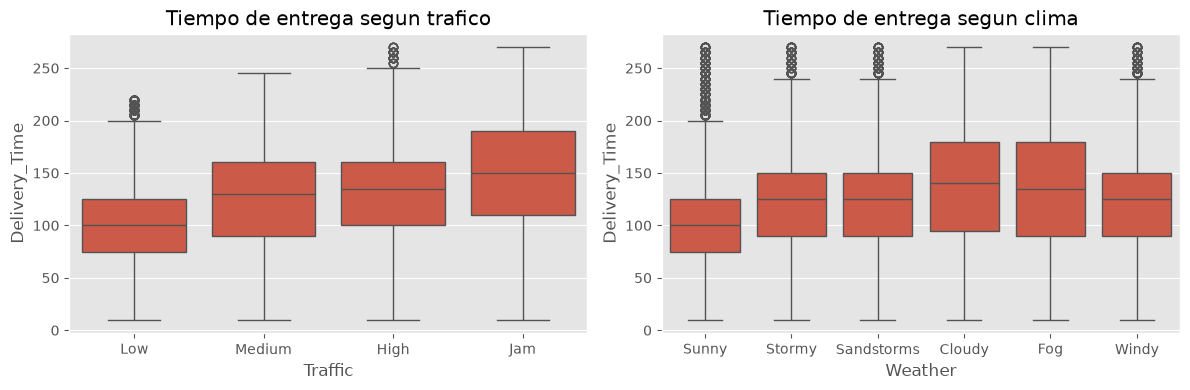

In [9]:
# Tiempo de entrega segun trafico y clima
fig, ax=plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(data=df, x=df["Traffic"].str.strip(), y="Delivery_Time", order=["Low","Medium","High","Jam"], ax=ax[0])
ax[0].set_title("Tiempo de entrega segun trafico")
sns.boxplot(data=df, x="Weather", y="Delivery_Time", ax=ax[1])
ax[1].set_title("Tiempo de entrega segun clima")
plt.tight_layout()
plt.show()

## 3. Variable objetivo: nivel de retraso (5 clases)

El dataset no trae una clase: trae los minutos de entrega (`Delivery_Time`). Construimos 5 niveles con cortes de negocio. **Supuesto del grupo:** la promesa de servicio es entregar en **2 horas**; sobre eso, el retraso se gradúa cada media hora.

| Clase | Nombre | Tiempo de entrega | Qué significa para la empresa |
|---|---|---|---|
| 0 | Rápida | hasta 60 min | Mejor que lo prometido |
| 1 | A tiempo | 61 a 120 min | Dentro de la promesa |
| 2 | Retraso leve | 121 a 150 min | Hasta media hora tarde |
| 3 | Retraso moderado | 151 a 180 min | Hasta una hora tarde |
| 4 | Retraso crítico | más de 180 min | Más de una hora tarde: reclamos, reembolsos y clientes perdidos |

Las clases son enteros de 0 a 4 desde el inicio, por lo que **no hace falta `LabelEncoder`**.

In [10]:
# Variable objetivo: 5 niveles segun el tiempo de entrega (minutos)
cortes=[0, 60, 120, 150, 180, np.inf]
nombres_clases=["Rapida", "A tiempo", "Retraso leve", "Retraso moderado", "Retraso critico"]
df["nivel_retraso"]=pd.cut(df["Delivery_Time"], bins=cortes, labels=[0,1,2,3,4]).astype(int)
# revisar que los cortes quedaron bien
df.groupby("nivel_retraso")["Delivery_Time"].agg(["min","max","count"])

,min,max,count
nivel_retraso,,,
0,10,60,4725
1,65,120,16622
2,125,150,10197
3,155,180,5786
4,185,270,6409


nivel_retraso
0    0.108
1    0.380
2    0.233
3    0.132
4    0.147
Name: proportion, dtype: float64


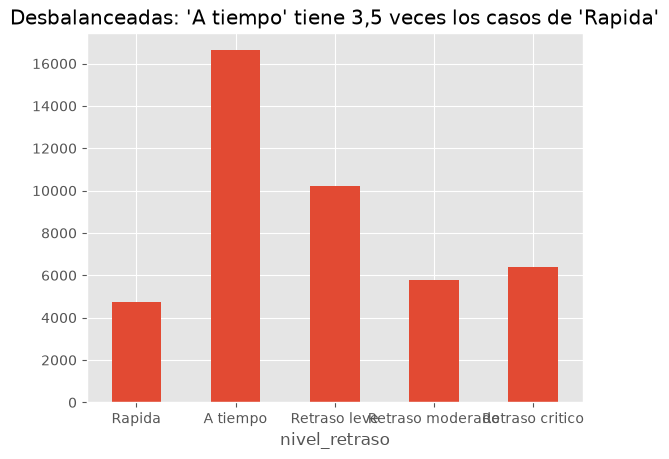

In [11]:
# esta balanceado?
print(df["nivel_retraso"].value_counts(normalize=True).sort_index().round(3))
df["nivel_retraso"].value_counts().sort_index().plot(kind='bar')
# personalizar
plt.xticks(range(5), nombres_clases, rotation=0)
plt.title("Desbalanceadas: 'A tiempo' tiene 3,5 veces los casos de 'Rapida'")
plt.show()

**Balance:** las clases están **desbalanceadas** (la mayor tiene unas 3,5 veces los casos de la menor), aunque todas tienen miles de casos, muy por sobre el mínimo de 50. Por eso:

- La métrica principal es el **F1 macro**: el promedio simple del F1 de las 5 clases, $F1_{macro}=\frac{1}{K}\sum_{k=1}^{K} F1_k$. Todas las clases pesan lo mismo; el *accuracy* premiaría acertar sobre todo la clase "A tiempo".
- La MLP lleva **SMOTE** dentro de su pipeline.

## 4. Matrices X, y y partición estratificada

In [12]:
# Crear matrices (X crudo: la limpieza la hace el pipeline)
# Order_ID es un identificador y Delivery_Time define la clase (seria fuga de datos)
X=df.drop(columns=["Order_ID", "Delivery_Time", "nivel_retraso"])
y=df["nivel_retraso"]
X.shape

(43739, 14)

In [13]:
# Particionar los datos
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=semilla,
                                                    stratify=y) # Garantiza el mismo porcentaje de cada clase en train y test
pd.DataFrame({"Train": y_train.value_counts(normalize=True).sort_index(),
              "Test": y_test.value_counts(normalize=True).sort_index()}).round(3)

,Train,Test
nivel_retraso,,
0,0.108,0.108
1,0.380,0.380
2,0.233,0.233
3,0.132,0.132
4,0.147,0.147


## 5. Preprocesado (dentro del pipeline)

Dos pasos, y los dos van **dentro del pipeline**, para que todo lo que se calcula con datos (como la mediana) salga **solo del entrenamiento** de cada fold:

**Paso 1 · `crear_variables` (`FunctionTransformer`):** limpieza y variables nuevas, fila por fila.
- Quitar espacios de las categorías y convertir el texto `"NaN"` en faltante.
- Recortar `Agent_Rating` a 5.
- `distancia_km`: distancia entre tienda y cliente con la fórmula de *haversine* (distancia sobre la Tierra a partir de latitud y longitud), usando el valor absoluto de las coordenadas de la tienda.
- `hora_pedido`, `espera_retiro_min` (minutos entre el pedido y el retiro) y `dia_semana` (0 = lunes).
- Se eliminan las coordenadas, la fecha y las horas originales: ya quedaron resumidas.

**Paso 2 · `ColumnTransformer`:**
- Numéricas → faltantes con la **mediana** (`SimpleImputer`).
- `Traffic` → faltantes con el valor más frecuente y números 0 a 3 respetando el orden Low < Medium < High < Jam (`OrdinalEncoder`).
- `Weather`, `Vehicle`, `Area` y `Category` → faltantes con el más frecuente y una columna 0/1 por categoría (`OneHotEncoder`).

El escalado y el balanceo no van aquí: solo los necesita la MLP (Parte A).

In [14]:
# Paso 1: limpieza y variables nuevas (fila por fila)
def crear_variables(X):
    X=X.copy()
    # categorias: quitar espacios y convertir el texto "NaN" en faltante
    for col in ["Weather", "Traffic", "Vehicle", "Area", "Category"]:
        X[col]=X[col].str.strip().replace("NaN", np.nan)
    # calificacion fuera de la escala 1 a 5
    X["Agent_Rating"]=X["Agent_Rating"].clip(upper=5)
    # distancia tienda - cliente en km (haversine); la tienda viene con signo negativo en algunas filas
    lat1=np.radians(X["Store_Latitude"].abs())
    lon1=np.radians(X["Store_Longitude"].abs())
    lat2=np.radians(X["Drop_Latitude"])
    lon2=np.radians(X["Drop_Longitude"])
    a=np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    X["distancia_km"]=6371*2*np.arcsin(np.sqrt(a))
    # hora del pedido y minutos de espera hasta el retiro
    pedido=pd.to_datetime(X["Order_Time"], format="%H:%M:%S", errors="coerce")  # "NaN" -> faltante
    retiro=pd.to_datetime(X["Pickup_Time"], format="%H:%M:%S", errors="coerce")
    X["hora_pedido"]=pedido.dt.hour
    X["espera_retiro_min"]=((retiro-pedido).dt.total_seconds()/60) % 1440   # % 1440: pedidos que cruzan la medianoche
    # dia de la semana (0 = lunes)
    X["dia_semana"]=pd.to_datetime(X["Order_Date"]).dt.dayofweek
    return X.drop(columns=["Store_Latitude", "Store_Longitude", "Drop_Latitude", "Drop_Longitude",
                           "Order_Date", "Order_Time", "Pickup_Time"])

# Probar el paso por separado
crear_variables(X_train).head()

,Agent_Age,Agent_Rating,Weather,Traffic,Vehicle,Area,Category,distancia_km,hora_pedido,espera_retiro_min,dia_semana
13930,25,4.9,Windy,Low,scooter,Urban,Pet Supplies,3.108988,9.0,10.0,4
18348,29,4.9,Stormy,Low,scooter,Metropolitian,Toys,16.659904,23.0,5.0,5
24817,29,4.9,Cloudy,Low,scooter,Metropolitian,Apparel,19.916195,22.0,10.0,2
29257,25,4.9,Cloudy,Medium,motorcycle,Urban,Kitchen,20.180909,18.0,15.0,4
21538,30,4.8,Windy,Low,scooter,Metropolitian,Pet Supplies,17.137880,22.0,15.0,6


In [15]:
# Definir variables (despues del paso 1)
cols_numericas=["Agent_Age", "Agent_Rating", "distancia_km", "hora_pedido", "espera_retiro_min", "dia_semana"]
cols_ordinal=["Traffic"]   # trafico: Low < Medium < High < Jam
cols_nominal=["Weather", "Vehicle", "Area", "Category"]   # categorias sin orden

In [16]:
# preprocesado
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline # flujo
# paso 1 del pipeline
variables=FunctionTransformer(crear_variables)
# paso 2 del pipeline: en las categoricas primero se imputa y luego se codifica
preprocesador=ColumnTransformer(transformers=[
    ("numericas", SimpleImputer(strategy="median"), cols_numericas), # faltantes -> mediana
    ("ordinal", Pipeline(steps=[("imputar", SimpleImputer(strategy="most_frequent")),
                                ("codificar", OrdinalEncoder(categories=[["Low","Medium","High","Jam"]]))]), cols_ordinal),
    ("nominal", Pipeline(steps=[("imputar", SimpleImputer(strategy="most_frequent")),
                                ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cols_nominal)],
    verbose_feature_names_out=False)
# Probar los dos pasos por separado (solo para mirar el resultado)
X_prep=preprocesador.fit_transform(variables.fit_transform(X_train))
print("Columnas despues del preprocesado:", X_prep.shape[1])
print("Faltantes despues del preprocesado:", np.isnan(X_prep).sum())
pd.DataFrame(X_prep, columns=preprocesador.get_feature_names_out()).head()

Columnas despues del preprocesado: 37
Faltantes despues del preprocesado: 0


,Agent_Age,Agent_Rating,distancia_km,hora_pedido,espera_retiro_min,dia_semana,Traffic,Weather_Cloudy,Weather_Fog,Weather_Sandstorms,...,Category_Home,Category_Jewelry,Category_Kitchen,Category_Outdoors,Category_Pet Supplies,Category_Shoes,Category_Skincare,Category_Snacks,Category_Sports,Category_Toys
0,25.0,4.9,3.108988,9.0,10.0,4.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,29.0,4.9,16.659904,23.0,5.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,29.0,4.9,19.916195,22.0,10.0,2.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,25.0,4.9,20.180909,18.0,15.0,4.0,1.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,30.0,4.8,17.137880,22.0,15.0,6.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


---
# Parte A. Red neuronal MLP

Es el modelo de referencia, con el mismo flujo de clases: **variables → preprocesado → balanceo (SMOTE) → escalado → modelo**.

- **SMOTE** crea casos sintéticos de las clases con menos casos hasta igualarlas. Va **dentro del pipeline**: en la validación cruzada se aplica solo al entrenamiento de cada fold, y el fold de validación y el test se quedan con datos reales.
- **Escalado** (`StandardScaler`): la red ajusta sus pesos con descenso de gradiente, y variables en escalas muy distintas (minutos vs. 0/1) hacen que el ajuste sea lento e inestable.
- **Multiclase:** `MLPClassifier` pone **5 neuronas de salida con softmax** y asigna la clase de mayor probabilidad (argmax). El código del modelo es el mismo del caso binario; solo cambian la métrica (`f1_macro`) y la lectura de `predict_proba` (5 columnas).

**Validación cruzada:** `StratifiedKFold` de 5 folds, igual que en clases.

In [17]:
# Flujo: Preprocesado + balanceo + escalado + modelo
from imblearn.over_sampling import SMOTE # Balanceo
from sklearn.preprocessing import StandardScaler # Escalado (la red lo necesita)
from sklearn.neural_network import MLPClassifier # Red neuronal multicapa
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, f1_score, ConfusionMatrixDisplay
 # Implementemos el flujo
nn=Pipeline(steps=[
    ("variables", variables),
    ("preprocesado", preprocesador),
    ("balanceo", SMOTE(random_state=semilla)),
    ("escalado", StandardScaler()),
    ("modelo", MLPClassifier(random_state=semilla, hidden_layer_sizes=(32,16), max_iter=500, early_stopping=True))
])
# validacion cruzada estratificada de 5 folds
cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
# F1 macro de validacion cruzada y ajuste final (se mide el tiempo de ambos)
inicio=time()
f1_cv_nn=cross_val_score(nn, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
nn.fit(X_train,y_train)
tiempo_nn=time()-inicio
print("F1 macro por fold:", f1_cv_nn.round(3))
print("F1 macro validacion cruzada:", f1_cv_nn.mean().round(3))
print("Tiempo (s):", round(tiempo_nn,1))

F1 macro por fold: [0.616 0.628 0.605 0.607 0.607]
F1 macro validacion cruzada: 0.612
Tiempo (s): 15.7


In [18]:
# Predicciones MLP base
inicio=time()
y_pred_nn=nn.predict(X_test)
tiempo_pred_nn=time()-inicio
y_pred_prob_nn=nn.predict_proba(X_test)   # 5 columnas: una probabilidad por clase
# Tabla
tabla_nn=pd.DataFrame({"Real":y_test, "Prediccion":y_pred_nn,
                       "Prob. prediccion":y_pred_prob_nn.max(axis=1),       # probabilidad de la clase elegida (argmax)
                       "Prob. retraso critico":y_pred_prob_nn[:,4]})        # clase 4, la que mas cuesta
tabla_nn.head(10).round(3)

,Real,Prediccion,Prob. prediccion,Prob. retraso critico
43308,3,3,0.972,0.012
34808,4,3,0.636,0.360
30711,1,1,0.555,0.000
36290,2,1,0.562,0.002
26373,1,1,0.563,0.000
17628,0,1,0.808,0.000
6583,1,1,0.509,0.004
43189,2,1,0.725,0.000
18859,0,0,0.759,0.000
33442,3,3,0.533,0.217


In [19]:
# Ajuste de hiperparametros de la MLP
from scipy.stats import loguniform
grilla_nn={
    "modelo__hidden_layer_sizes":[(16,),(32,),(64,),(32,16),(64,32),(128,64),(64,32,16)], # capas y neuronas
    "modelo__activation":["relu","tanh"], # funcion de activacion
    "modelo__alpha":loguniform(1e-5,1e-1), # regularizacion L2
    "modelo__learning_rate_init":loguniform(1e-4,1e-1), # tasa de aprendizaje
    "modelo__batch_size":[32,64,128] # tamano del lote
}
busqueda_nn=RandomizedSearchCV(nn,
                               param_distributions=grilla_nn,
                               n_iter=20, # combinaciones a probar
                               scoring="f1_macro", # multiclase: todas las clases pesan lo mismo
                               cv=cv,
                               n_jobs=-1,
                               random_state=semilla)
# ajuste
inicio=time()
busqueda_nn.fit(X_train,y_train)
tiempo_nn_best=time()-inicio
print("F1 macro validacion cruzada:", busqueda_nn.best_score_.round(3))
print("Tiempo (s):", round(tiempo_nn_best,1))
busqueda_nn.best_params_

F1 macro validacion cruzada: 0.619
Tiempo (s): 422.4


{'modelo__activation': 'tanh',
 'modelo__alpha': np.float64(0.00014969038728244706),
 'modelo__batch_size': 32,
 'modelo__hidden_layer_sizes': (32, 16),
 'modelo__learning_rate_init': np.float64(0.00017304928543622144)}

In [20]:
# Las 5 mejores combinaciones de la busqueda
resultados_nn=pd.DataFrame(busqueda_nn.cv_results_)
resultados_nn[["param_modelo__hidden_layer_sizes", "param_modelo__activation", "param_modelo__alpha",
               "param_modelo__learning_rate_init", "param_modelo__batch_size",
               "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False).head().round(4)

,param_modelo__hidden_layer_sizes,param_modelo__activation,param_modelo__alpha,param_modelo__learning_rate_init,param_modelo__batch_size,mean_test_score,std_test_score
10,"(32, 16)",tanh,0.0001,0.0002,32,0.6192,0.0068
13,"(32, 16)",relu,0.0152,0.0013,32,0.6185,0.0069
6,"(16,)",tanh,0.0001,0.0005,64,0.6167,0.0124
8,"(32, 16)",tanh,0.0054,0.0033,32,0.6129,0.0050
7,"(128, 64)",tanh,0.0291,0.0048,64,0.6104,0.0103


In [21]:
# Comparar: MLP base vs MLP ajustada
nn_best=busqueda_nn.best_estimator_
inicio=time()
y_pred_nn_best=nn_best.predict(X_test)
tiempo_pred_nn_best=time()-inicio
y_pred_prob_nn_best=nn_best.predict_proba(X_test)
print("MLP base")
print(classification_report(y_test, y_pred_nn, target_names=nombres_clases, digits=3))
print("MLP ajustada")
print(classification_report(y_test, y_pred_nn_best, target_names=nombres_clases, digits=3))

MLP base
                  precision    recall  f1-score   support

          Rapida      0.767     0.675     0.718       945
        A tiempo      0.702     0.683     0.692      3325
    Retraso leve      0.480     0.580     0.525      2039
Retraso moderado      0.543     0.442     0.487      1157
 Retraso critico      0.684     0.683     0.684      1282

        accuracy                          0.626      8748
       macro avg      0.635     0.613     0.621      8748
    weighted avg      0.634     0.626     0.628      8748

MLP ajustada
                  precision    recall  f1-score   support

          Rapida      0.731     0.684     0.706       945
        A tiempo      0.686     0.685     0.685      3325
    Retraso leve      0.475     0.534     0.503      2039
Retraso moderado      0.550     0.483     0.514      1157
 Retraso critico      0.698     0.672     0.684      1282

        accuracy                          0.621      8748
       macro avg      0.628     0.611     0.6

---
# Parte B. TabPFN: un Transformer preentrenado para tablas

**TabPFN** (*Tabular Prior-data Fitted Network*) es un Transformer que **ya fue entrenado** por Prior Labs con millones de tablas **sintéticas**, generadas con modelos causales al azar (relaciones lineales y no lineales, ruido, variables irrelevantes, clases desbalanceadas).

- **Preentrenado:** sus pesos quedan fijos. No aprende pesos con nuestros datos.
- **Aprendizaje en contexto:** en `fit` guarda el entrenamiento como **contexto**; en `predict` lee ese contexto junto con los casos nuevos y responde en **una sola pasada**. Aproxima la predicción bayesiana $p(y \mid x_{nuevo}, D)$.
- **Atención entre columnas:** dentro de una fila, cada variable mira a las otras (interacciones, por ejemplo tráfico × distancia).
- **Atención entre filas:** cada variable mira esa misma variable en los ejemplos de entrenamiento (casos parecidos). Las filas de test atienden a las de entrenamiento, pero no al revés.
- **`n_estimators`:** repite la pasada con distintas transformaciones de los datos y promedia, como un ensamble.

**¿Por qué TabPFN no lleva SMOTE ni escalado?**

| Paso | MLP | TabPFN |
|---|---|---|
| Escalado | Lo necesita: ajusta pesos con descenso de gradiente | No: no entrena pesos y **normaliza y transforma internamente** cada variable en cada estimador |
| SMOTE | Lo necesita para no ignorar las clases chicas al entrenar | No: se preentrenó con tablas desbalanceadas y lee las proporciones reales del contexto. Puntos sintéticos cambiarían ese contexto. Si hace falta, el desbalance se corrige en la salida con `balance_probabilities` |

Sí mantiene el mismo **preprocesado** (imputación y codificación), como en el notebook de clases, para que los cuatro modelos reciban las mismas variables.

**Límites:** según la presentación de clase, TabPFN-3 admite 1.000.000 de filas con hasta 200 variables, o 100.000 filas con 2.000 variables, y hasta 160 clases. El modelo que carga la librería 9.2.0 es TabPFN-3.5, que según su configuración también admite 1.000.000 de filas y 160 clases. Usamos 34.991 filas de entrenamiento, 37 variables y 5 clases: estamos dentro de los límites.

**Antes de ejecutar (Colab, GPU T4):** cada integrante crea su cuenta en https://ux.priorlabs.ai, acepta la licencia y guarda su API Key en los **Secretos de Colab** con el nombre `TABPFN_TOKEN`. **Nunca se escribe la API Key en el notebook.**

In [22]:
# Instalar TabPFN (en Colab; en local ya esta en el entorno)
try:
    import tabpfn
except ImportError:
    %pip install -q tabpfn

In [23]:
# Token de TabPFN (necesario para descargar los pesos del modelo la primera vez)
# La API Key NUNCA se escribe aqui: en Colab va en los Secretos; en local, en la variable de entorno TABPFN_TOKEN
import os
try:
    from google.colab import userdata
    os.environ["TABPFN_TOKEN"]=userdata.get("TABPFN_TOKEN")   # desde los Secretos de Colab
except ImportError:
    pass
print("Token cargado:", bool(os.environ.get("TABPFN_TOKEN")))   # solo dice si existe, no lo muestra

Token cargado: True


In [24]:
# Hardware disponible (TabPFN necesita GPU con mas de 1.000 filas)
import torch
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    print("GPU de Apple (MPS)")
else:
    print("Solo CPU: TabPFN sera muy lento")

GPU de Apple (MPS)


In [25]:
# Flujo: Preprocesado + modelo TabPFN (sin balanceo ni escalado)
from tabpfn import TabPFNClassifier
pfn=Pipeline(steps=[
    ("variables", variables),
    ("preprocesado", preprocesador),
    ("modelo", TabPFNClassifier(random_state=semilla, device="auto"))
])
# ajuste: guarda los datos de entrenamiento como contexto (no entrena pesos)
inicio=time()
pfn.fit(X_train,y_train)
tiempo_fit_pfn=time()-inicio
print("Tiempo de fit (s):", round(tiempo_fit_pfn,1))
print("Pasadas por defecto (n_estimators):", pfn.named_steps["modelo"].n_estimators_)

Tiempo de fit (s): 1.1
Pasadas por defecto (n_estimators): 8


En TabPFN casi todo el trabajo ocurre en la predicción. Por eso calculamos `predict_proba` **una sola vez** y elegimos la clase de mayor probabilidad (*argmax*), que es justo lo que hace `predict` en multiclase. Así no se repite una pasada que en test demora varios minutos.

In [26]:
# Predicciones TabPFN base: aqui trabaja el Transformer (lee el contexto junto con los casos de test)
inicio=time()
y_pred_prob_pfn=pfn.predict_proba(X_test)
y_pred_pfn=pfn.classes_[y_pred_prob_pfn.argmax(axis=1)]   # clase con mayor probabilidad (argmax): es lo que hace predict
tiempo_pred_pfn=time()-inicio
print("Tiempo de prediccion en test (s):", round(tiempo_pred_pfn,1))
# Tabla
tabla_pfn=pd.DataFrame({"Real":y_test, "Prediccion":y_pred_pfn,
                        "Prob. prediccion":y_pred_prob_pfn.max(axis=1),
                        "Prob. retraso critico":y_pred_prob_pfn[:,4]})
tabla_pfn.head(10).round(3)

Tiempo de prediccion en test (s): 298.7


,Real,Prediccion,Prob. prediccion,Prob. retraso critico
43308,3,3,0.998,0.002
34808,4,3,0.596,0.404
30711,1,1,0.640,0.000
36290,2,1,0.565,0.000
26373,1,1,0.478,0.000
17628,0,1,0.906,0.000
6583,1,2,0.466,0.000
43189,2,2,0.511,0.000
18859,0,1,0.647,0.000
33442,3,2,0.416,0.285


### Ajuste de hiperparámetros de TabPFN

Como el modelo ya viene preentrenado, se ajustan pocos hiperparámetros en una grilla pequeña con **GridSearchCV**: 2 × 2 = 4 combinaciones × 3 folds = 12 ajustes.

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `n_estimators` | 4, 8 | Cuántas pasadas se promedian (ensamble) |
| `balance_probabilities` | False, True | Si es `True`, corrige las probabilidades según la proporción de cada clase en el entrenamiento: sube la probabilidad de las clases con pocos casos y baja la de las clases con muchos. Solo cambia la salida, no el contexto |

In [27]:
# Ajuste de hiperparametros de TabPFN
from sklearn.model_selection import GridSearchCV
grilla_pfn={
    "modelo__n_estimators":[4,8], # pasadas promediadas (ensamble)
    "modelo__balance_probabilities":[False,True] # corregir el desbalance de clases
}
# validacion cruzada de 3 folds (como en clases: TabPFN es mas pesado de evaluar)
cv3=StratifiedKFold(n_splits=3, shuffle=True, random_state=semilla)
busqueda_pfn=GridSearchCV(pfn,
                          param_grid=grilla_pfn,
                          scoring="f1_macro", # multiclase: todas las clases pesan lo mismo
                          cv=cv3)
# ajuste
inicio=time()
busqueda_pfn.fit(X_train,y_train)
tiempo_pfn_best=time()-inicio
print("F1 macro validacion cruzada:", busqueda_pfn.best_score_.round(3))
print("Tiempo (s):", round(tiempo_pfn_best,1))
busqueda_pfn.best_params_

F1 macro validacion cruzada: 0.648
Tiempo (s): 1336.6


{'modelo__balance_probabilities': False, 'modelo__n_estimators': 4}

In [28]:
# Las 4 combinaciones de la grilla
resultados_pfn=pd.DataFrame(busqueda_pfn.cv_results_)
resultados_pfn[["param_modelo__n_estimators", "param_modelo__balance_probabilities",
                "mean_test_score", "std_test_score", "mean_fit_time", "mean_score_time"]
               ].sort_values("mean_test_score", ascending=False).round(4)

,param_modelo__n_estimators,param_modelo__balance_probabilities,mean_test_score,std_test_score,mean_fit_time,mean_score_time
0,4,False,0.6478,0.0010,1.4823,63.6873
1,8,False,0.6470,0.0018,0.9496,152.2725
2,4,True,0.6319,0.0030,2.9455,79.5836
3,8,True,0.6315,0.0029,1.3919,142.9116


In [29]:
# F1 de validacion cruzada del TabPFN base
# El modelo base (n_estimators por defecto = 8, balance_probabilities=False) es una de las 4 combinaciones
# de la grilla, con los mismos 3 folds: se toma de ahi en vez de repetir su validacion cruzada
fila_base=resultados_pfn[(resultados_pfn["param_modelo__n_estimators"]==8) &
                         (resultados_pfn["param_modelo__balance_probabilities"]==False)].iloc[0]
f1_cv_pfn=fila_base["mean_test_score"]
tiempo_pfn=3*(fila_base["mean_fit_time"]+fila_base["mean_score_time"]) + tiempo_fit_pfn   # validacion cruzada + ajuste final
print("F1 macro por fold:", [round(fila_base[f"split{i}_test_score"],3) for i in range(3)])
print("F1 macro validacion cruzada (TabPFN base):", round(f1_cv_pfn,3))
print("Tiempo (s):", round(tiempo_pfn,1))

F1 macro por fold: [np.float64(0.649), np.float64(0.648), np.float64(0.645)]
F1 macro validacion cruzada (TabPFN base): 0.647
Tiempo (s): 460.7


In [30]:
# Comparar: TabPFN base vs TabPFN ajustado
pfn_best=busqueda_pfn.best_estimator_
inicio=time()
y_pred_prob_pfn_best=pfn_best.predict_proba(X_test)
y_pred_pfn_best=pfn_best.classes_[y_pred_prob_pfn_best.argmax(axis=1)]
tiempo_pred_pfn_best=time()-inicio
print("TabPFN base")
print(classification_report(y_test, y_pred_pfn, target_names=nombres_clases, digits=3))
print("TabPFN ajustado")
print(classification_report(y_test, y_pred_pfn_best, target_names=nombres_clases, digits=3))

OOM: halving row_chunk_size to 20695


TabPFN base
                  precision    recall  f1-score   support

          Rapida      1.000     0.576     0.731       945
        A tiempo      0.682     0.861     0.761      3325
    Retraso leve      0.543     0.531     0.537      2039
Retraso moderado      0.710     0.373     0.489      1157
 Retraso critico      0.699     0.766     0.731      1282

        accuracy                          0.675      8748
       macro avg      0.727     0.621     0.650      8748
    weighted avg      0.690     0.675     0.665      8748

TabPFN ajustado
                  precision    recall  f1-score   support

          Rapida      1.000     0.576     0.731       945
        A tiempo      0.682     0.856     0.760      3325
    Retraso leve      0.545     0.536     0.541      2039
Retraso moderado      0.701     0.377     0.490      1157
 Retraso critico      0.698     0.765     0.730      1282

        accuracy                          0.675      8748
       macro avg      0.725     0.622  

In [31]:
# Que cambia con balance_probabilities: probabilidad promedio de cada clase en test
pfn_bal=Pipeline(steps=[("variables", variables), ("preprocesado", preprocesador),
                        ("modelo", TabPFNClassifier(random_state=semilla, device="auto", balance_probabilities=True))])
pfn_bal.fit(X_train,y_train)
prob_bal=pfn_bal.predict_proba(X_test)
pd.DataFrame({"Proporcion real en train": y_train.value_counts(normalize=True).sort_index().values,
              "Prob. media sin balance": y_pred_prob_pfn.mean(axis=0),
              "Prob. media con balance": prob_bal.mean(axis=0)}, index=nombres_clases).round(3)

OOM: halving row_chunk_size to 20695


,Proporcion real en train,Prob. media sin balance,Prob. media con balance
Rapida,0.108,0.108,0.160
A tiempo,0.380,0.381,0.284
Retraso leve,0.233,0.237,0.250
Retraso moderado,0.132,0.129,0.157
Retraso critico,0.147,0.146,0.150


---
# Parte C. Comparación final

Para cada modelo: F1 macro de **validación cruzada** (estimación honesta, solo con entrenamiento), de **entrenamiento** (si es mucho mayor que test, hay sobreajuste) y de **test** (datos nuevos), más el tiempo.

**Tiempo (`Tiempo_s`):** en los modelos base es la validación cruzada más el ajuste final; en los ajustados, la búsqueda completa (que incluye el reajuste del mejor modelo). `Prediccion_test_s` es lo que demora cada modelo en predecir las 8.748 entregas de test. En TabPFN casi todo el tiempo está en la predicción, porque ahí trabaja el Transformer.

**F1 de entrenamiento:** se mide sobre una **muestra fija y estratificada de 7.000 filas** del entrenamiento, la misma para los cuatro modelos. TabPFN demora varios minutos por cada 7.000 filas que predice; con las 34.991 filas serían cerca de 20 minutos por modelo. Con 7.000 filas la estimación ya es estable para detectar sobreajuste.

In [32]:
# Muestra fija de 7.000 filas de entrenamiento para el F1 de entrenamiento (la misma para los cuatro modelos)
X_muestra, _, y_muestra, _ = train_test_split(X_train, y_train,
                                              train_size=7000,
                                              random_state=semilla,
                                              stratify=y_train)

# Funcion que evalua un pipeline ya ajustado (las predicciones de test ya estan calculadas)
def evaluar_modelo(modelo, y_pred, f1_cv, tiempo, tiempo_pred):
    return {"F1_cv": f1_cv,
            "F1_train": f1_score(y_muestra, modelo.predict(X_muestra), average="macro"),
            "F1_test": f1_score(y_test, y_pred, average="macro"),
            "Tiempo_s": tiempo,
            "Prediccion_test_s": tiempo_pred}

# Tabla de comparacion de los cuatro modelos
filas=[]
modelos={"MLP base":        (nn,       y_pred_nn,       f1_cv_nn.mean(),         tiempo_nn,       tiempo_pred_nn),
         "MLP ajustada":    (nn_best,  y_pred_nn_best,  busqueda_nn.best_score_,  tiempo_nn_best,  tiempo_pred_nn_best),
         "TabPFN base":     (pfn,      y_pred_pfn,      f1_cv_pfn,               tiempo_pfn,      tiempo_pred_pfn),
         "TabPFN ajustado": (pfn_best, y_pred_pfn_best, busqueda_pfn.best_score_, tiempo_pfn_best, tiempo_pred_pfn_best)}
for nombre, (modelo, y_pred, f1_cv, tiempo, tiempo_pred) in modelos.items():
    metricas=evaluar_modelo(modelo, y_pred, f1_cv, tiempo, tiempo_pred)
    metricas["Modelo"]=nombre
    filas.append(metricas)
comparacion=pd.DataFrame(filas).set_index("Modelo")
comparacion["Brecha"]=comparacion["F1_train"]-comparacion["F1_test"]   # sobreajuste
comparacion.round(3)

OOM: halving row_chunk_size to 20695


,F1_cv,F1_train,F1_test,Tiempo_s,Prediccion_test_s,Brecha
Modelo,,,,,,
MLP base,0.612,0.664,0.621,15.705,0.039,0.043
MLP ajustada,0.619,0.650,0.619,422.384,0.022,0.031
TabPFN base,0.647,0.659,0.650,460.738,298.720,0.009
TabPFN ajustado,0.648,0.658,0.650,1336.576,123.251,0.008


**Cómo leer la tabla de arriba**

| Columna | Sobre qué filas se mide |
|---|---|
| `F1_cv` | Promedio de los 5 folds de validación cruzada sobre las **34.991 filas** de entrenamiento (en los modelos ajustados, el `best_score_` de la búsqueda) |
| `F1_train` | **Muestra fija y estratificada de 7.000 filas** del entrenamiento, la misma para los cuatro modelos (ver la celda anterior). No son las 34.991 filas |
| `F1_test` | Las **8.748 filas** de test |
| `Brecha` | `F1_train` − `F1_test`: estimación del sobreajuste con la muestra de 7.000 filas |
| `Tiempo_s` | Validación cruzada o búsqueda + ajuste final |
| `Prediccion_test_s` | Predecir las 8.748 filas de test |

**Tiempos y hardware (GPU de Apple, MPS).** Todos los tiempos se midieron en un MacBook Pro con chip **Apple M5 Pro** (48 GB). TabPFN corre en la GPU de Apple (MPS) porque se crea con `device="auto"`; la MLP de scikit-learn corre siempre en CPU, así que la GPU no cambia sus tiempos. Para medir el impacto se ajustó TabPFN ajustado (4 pasadas) con las 34.991 filas de entrenamiento y se predijo una muestra fija de 500 pedidos de test en cada dispositivo (`scripts/medir_tiempos_dispositivo.py`, `resultados/tiempos_dispositivo.csv`):

| Dispositivo | Predecir 500 pedidos | Diferencia de probabilidad |
|---|---|---|
| GPU Apple (MPS) | 103 s | referencia |
| CPU del mismo Mac | 1.033 s (**10 veces más lento**) | máximo 0,004 |

Lecturas: (1) sin GPU, TabPFN sería unas 10 veces más lento; por defecto ni siquiera acepta correr en CPU con más de 5.000 filas de entrenamiento. (2) La mayor parte del tiempo de predicción es un costo fijo por llamada: 500 pedidos tardaron 103 s y las 8.748 de test, 123 s en esta tabla. (3) Los tiempos de TabPFN dependen del equipo: en otra GPU, como la T4 de Colab, serían distintos, y entre ejecuciones varían según la carga de la GPU (en esta ejecución la GPU se quedó corta de memoria y TabPFN partió el trabajo en trozos más chicos: aviso `OOM: halving row_chunk_size`). Por eso los tiempos sirven para comparar los modelos entre sí en este equipo, no como cifra absoluta.


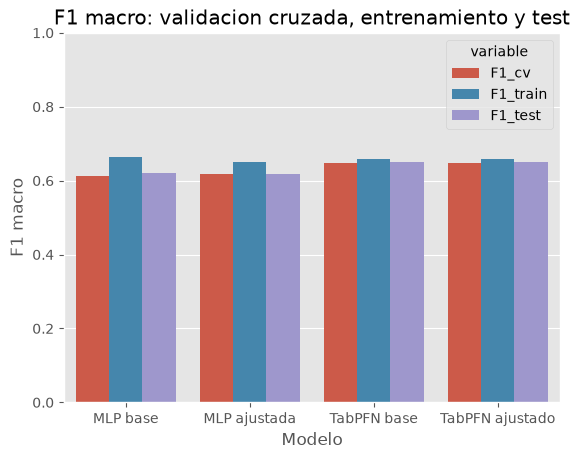

In [33]:
# Grafico: entrenamiento vs validacion vs test
comparacion_largo=comparacion.reset_index().melt(id_vars="Modelo", value_vars=["F1_cv", "F1_train", "F1_test"])
sns.barplot(data=comparacion_largo, x="Modelo", y="value", hue="variable")
plt.ylabel("F1 macro")
plt.ylim(0, 1)
plt.title("F1 macro: validacion cruzada, entrenamiento y test")
plt.show()

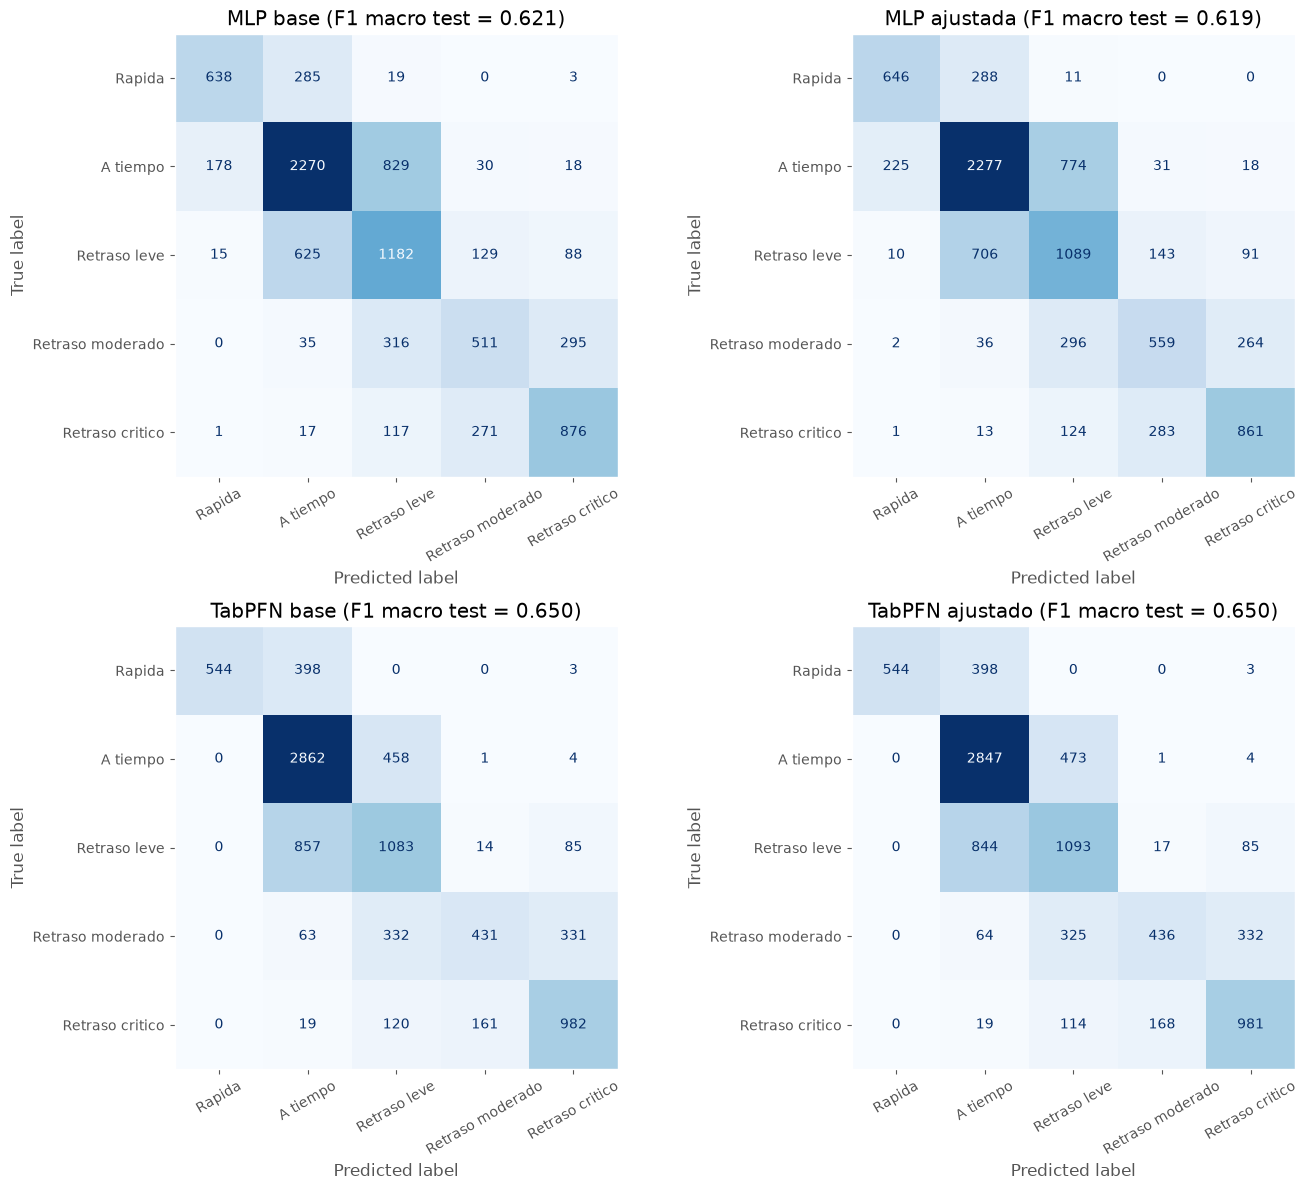

In [34]:
# Matrices de confusion 5 x 5 de los cuatro modelos (test)
predicciones={"MLP base": y_pred_nn, "MLP ajustada": y_pred_nn_best,
              "TabPFN base": y_pred_pfn, "TabPFN ajustado": y_pred_pfn_best}
fig, ax=plt.subplots(2, 2, figsize=(14,12))
for eje, (nombre, pred) in zip(ax.ravel(), predicciones.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=nombres_clases, cmap="Blues",
                                            colorbar=False, xticks_rotation=30, ax=eje)
    eje.set_title(f"{nombre} (F1 macro test = {comparacion.loc[nombre,'F1_test']:.3f})")
    eje.grid(False)
plt.tight_layout()
plt.show()

Mejor modelo: TabPFN ajustado


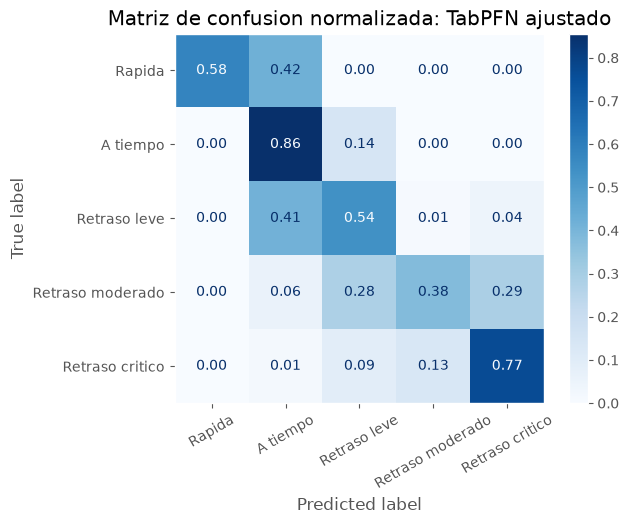

                  precision    recall  f1-score   support

          Rapida      1.000     0.576     0.731       945
        A tiempo      0.682     0.856     0.760      3325
    Retraso leve      0.545     0.536     0.541      2039
Retraso moderado      0.701     0.377     0.490      1157
 Retraso critico      0.698     0.765     0.730      1282

        accuracy                          0.675      8748
       macro avg      0.725     0.622     0.650      8748
    weighted avg      0.689     0.675     0.665      8748



In [35]:
# Mejor modelo segun validacion cruzada (no segun test, para no elegir con los datos de prueba)
mejor_nombre=comparacion["F1_cv"].idxmax()
mejor_pred=predicciones[mejor_nombre]
print("Mejor modelo:", mejor_nombre)
# Matriz normalizada por fila: cada fila suma 1 (recall de cada clase en la diagonal)
ConfusionMatrixDisplay.from_predictions(y_test, mejor_pred, display_labels=nombres_clases, cmap="Blues",
                                        normalize="true", values_format=".2f", xticks_rotation=30)
plt.title(f"Matriz de confusion normalizada: {mejor_nombre}")
plt.grid(False)
plt.show()
print(classification_report(y_test, mejor_pred, target_names=nombres_clases, digits=3))

In [36]:
# Que clases se confunden mas entre si (errores del mejor modelo, sin la diagonal)
from sklearn.metrics import confusion_matrix
matriz=pd.DataFrame(confusion_matrix(y_test, mejor_pred), index=nombres_clases, columns=nombres_clases)
errores=matriz.stack().reset_index()
errores.columns=["Real", "Prediccion", "Casos"]
errores[errores["Real"]!=errores["Prediccion"]].sort_values("Casos", ascending=False).head(6)

,Real,Prediccion,Casos
11,Retraso leve,A tiempo,844
7,A tiempo,Retraso leve,473
1,Rapida,A tiempo,398
19,Retraso moderado,Retraso critico,332
17,Retraso moderado,Retraso leve,325
23,Retraso critico,Retraso moderado,168


In [37]:
# Guardar resultados
os.makedirs("resultados", exist_ok=True)
comparacion.round(3).to_csv("resultados/comparacion_modelos.csv")   # mismos 3 decimales que la tabla de arriba
matriz.to_csv("resultados/matriz_confusion_mejor.csv")
pd.DataFrame(classification_report(y_test, mejor_pred, target_names=nombres_clases, output_dict=True)).T.round(4).to_csv("resultados/reporte_mejor.csv")
joblib.dump(nn_best, "resultados/mlp_ajustada.joblib")   # pipeline completo de la MLP (TabPFN se vuelve a ajustar en segundos)
print("Guardado en resultados/")

Guardado en resultados/


---
# Parte D. Conclusiones

Todas las cifras salen de las celdas anteriores y de `resultados/comparacion_modelos.csv`.

| Pregunta | Respuesta |
|---|---|
| **¿Qué modelo ganó?** | **TabPFN ajustado** (`n_estimators=4`, `balance_probabilities=False`): F1 macro de 0,648 en validación cruzada y **0,650 en test**, contra 0,621 de la mejor MLP en test (**+2,9 puntos**). Se eligió por validación cruzada, no por test. |
| **¿Mejoró el ajuste?** | Casi nada en F1. **MLP:** la validación cruzada subió de 0,612 a 0,619, pero el test bajó de 0,621 a 0,619; la diferencia es menor que la variación entre folds (desviación ≈ 0,007). **TabPFN:** base y ajustado empatan (0,647 y 0,648 en validación, 0,650 en test). La ganancia real del ajuste de TabPFN es de **costo**: con 4 pasadas en vez de 8 predice el test en 123 s en vez de 299 s, con el mismo F1. |
| **¿Sobreajuste?** | Bajo en los cuatro. Brecha entre entrenamiento y test: 0,031 a 0,043 en la MLP y 0,008 a 0,009 en TabPFN. |
| **`balance_probabilities=True`** | Empeoró el F1 macro en validación cruzada (0,632 contra 0,648). Sube la probabilidad media de las clases chicas (Rápida de 0,108 a 0,160; Retraso moderado de 0,129 a 0,157) y baja la de "A tiempo" (de 0,381 a 0,284). El modelo predice más las clases chicas, pero se equivoca más. |
| **Código y tiempo** | La MLP necesita SMOTE, escalado y una búsqueda sobre 5 hiperparámetros: 16 s el modelo base y 7,0 min la búsqueda. TabPFN no lleva SMOTE ni escalado y su grilla tiene 4 combinaciones, pero su costo está en predecir: 5,0 min para el test con 8 pasadas y 22 min la grilla en la GPU del Mac (Apple M5 Pro, MPS). En CPU TabPFN sería unas 10 veces más lento (medición bajo la tabla de la Parte C); la MLP no usa GPU. Los tiempos varían entre ejecuciones según la carga de la GPU. |

**Matriz de confusión del mejor modelo**

- Las confusiones están entre **clases vecinas**, cuyos cortes distan solo 30 minutos: Retraso leve → A tiempo (844), A tiempo → Retraso leve (473), Rápida → A tiempo (398) y Retraso moderado → Retraso crítico (332).
- **Rápida** tiene precisión 1,000 y recall 0,576. En los datos, **todos** los pedidos de la categoría Grocery llegan en menos de una hora (2.691 de 2.691). El modelo aprendió esa regla, pero confunde con "A tiempo" las otras entregas rápidas (2.034 que no son Grocery).
- **El error más costoso** es predecir "Rápida" o "A tiempo" cuando el retraso es crítico: la empresa no actúa y el cliente espera más de 3 horas. Pasa en **19 de 1.282** retrasos críticos (1,5%). El recall de la clase crítica es **0,765**.
- **Falsas alarmas:** 424 de los 1.405 pedidos marcados como críticos no lo eran (precisión 0,698), y la mayoría eran retrasos moderados (332). Para el negocio es un error barato, porque esos pedidos igual llegaban tarde.

**Recomendación:** usar **TabPFN ajustado** en el Hito 2 (simulador what-if con `predict_proba` y plan priorizado de pedidos con riesgo de retraso crítico). Su limitación es el costo de predecir miles de pedidos a la vez; para un ranking diario es aceptable.


---
# Parte E. Plan de acción priorizado (Hito 2)

Con el mejor modelo ordenamos los pedidos según su **probabilidad de retraso crítico** y revisamos primero los más riesgosos, con una capacidad limitada.

| Elemento | Decisión |
|---|---|
| **Clase crítica** | **4, Retraso crítico** (más de 3 horas). Es la que genera reclamos, devolución del despacho y pérdida de clientes. Además es la que el modelo detecta mejor entre las clases de retraso (recall 0,765). |
| **Acción** | Un **coordinador de despacho** revisa el pedido al momento del retiro: reasigna el repartidor si su calificación es baja, prioriza la ruta y **avisa al cliente** antes de que el retraso ocurra. |
| **Capacidad** | **80 pedidos al día**: una persona, jornada de 8 horas, unos 6 minutos por pedido (8 × 60 / 6 = 80). La operación tiene en promedio unos 1.000 pedidos diarios, así que se revisa cerca del **8 %**. |
| **Período de evaluación** | El test (20 % de los pedidos). Se revisa la misma proporción de pedidos que permite la capacidad. |

In [38]:
# Probabilidad de retraso critico (clase 4) del mejor modelo, en test
probabilidades={"MLP base": y_pred_prob_nn, "MLP ajustada": y_pred_prob_nn_best,
                "TabPFN base": y_pred_prob_pfn, "TabPFN ajustado": y_pred_prob_pfn_best}
prob_mejor=probabilidades[mejor_nombre]
clase_critica=4
plan=pd.DataFrame({"Order_ID": df.loc[X_test.index, "Order_ID"],
                   "Fecha": df.loc[X_test.index, "Order_Date"],
                   "Prob_critico": prob_mejor[:, clase_critica],
                   "Clase_predicha": prob_mejor.argmax(axis=1),   # las clases son 0 a 4: el indice es la clase
                   "Clase_real": y_test,
                   "Es_critico": (y_test==clase_critica).astype(int)}, index=X_test.index)
print("Pedidos en test:", len(plan))
print("Retrasos criticos reales:", plan["Es_critico"].sum(), f"({plan['Es_critico'].mean():.1%})")

Pedidos en test: 8748
Retrasos criticos reales: 1282 (14.7%)


In [39]:
# Supuesto de capacidad: 1 coordinador revisa 80 pedidos al dia (6 min por pedido en 8 h)
pedidos_dia=df.groupby("Order_Date").size().mean()   # pedidos diarios promedio en los datos
capacidad_dia=80
capacidad_pct=capacidad_dia/pedidos_dia               # proporcion de pedidos que se alcanza a revisar
k=int(round(capacidad_pct*len(plan)))                 # la misma proporcion aplicada al test
dias_test=len(plan)/pedidos_dia                       # a cuantos dias de operacion equivale el test
print(f"Pedidos diarios promedio: {pedidos_dia:.0f}")
print(f"Capacidad: {capacidad_dia} pedidos/dia = {capacidad_pct:.1%} de los pedidos")
print(f"En test se revisan los {k} pedidos con mayor probabilidad (equivale a {dias_test:.1f} dias)")

Pedidos diarios promedio: 994
Capacidad: 80 pedidos/dia = 8.0% de los pedidos
En test se revisan los 704 pedidos con mayor probabilidad (equivale a 8.8 dias)


### Ranking de casos

Los primeros pedidos a intervenir. La acción depende de lo que se puede cambiar en el pedido: si el repartidor tiene calificación baja, se reasigna; si no, se prioriza la ruta. En los dos casos se avisa al cliente.

In [40]:
# Ranking: pedidos ordenados de mayor a menor probabilidad de retraso critico
def asignar_accion(fila):
    if fila["Agent_Rating"]<4.5:
        return "Reasignar a repartidor con nota >= 4,5 y avisar al cliente"
    if fila["Traffic"]=="Jam":
        return "Ruta alternativa por congestion y avisar al cliente"
    return "Priorizar la ruta y avisar al cliente"

ranking=plan.join(variables.transform(X_test)[["Agent_Rating", "Traffic", "distancia_km"]])
ranking=ranking.sort_values("Prob_critico", ascending=False)
ranking["Prioridad"]=np.arange(1, len(ranking)+1)
ranking["Clase_predicha"]=[nombres_clases[c] for c in ranking["Clase_predicha"]]
ranking["Accion"]=ranking.apply(asignar_accion, axis=1)
ranking[["Prioridad", "Order_ID", "Prob_critico", "Clase_predicha", "Accion", "Es_critico"]].head(20).round(3)

,Prioridad,Order_ID,Prob_critico,Clase_predicha,Accion,Es_critico
43345,1,uyvg385808653,1.000,Retraso critico,"Reasignar a repartidor con nota >= 4,5 y avisa...",1
24847,2,ejmn539253779,1.000,Retraso critico,Ruta alternativa por congestion y avisar al cl...,1
40673,3,adye908869447,1.000,Retraso critico,"Reasignar a repartidor con nota >= 4,5 y avisa...",1
30335,4,xqlm229899010,1.000,Retraso critico,"Reasignar a repartidor con nota >= 4,5 y avisa...",1
28472,5,qwfv785480709,1.000,Retraso critico,Ruta alternativa por congestion y avisar al cl...,1
10876,6,czmv494892984,1.000,Retraso critico,"Reasignar a repartidor con nota >= 4,5 y avisa...",1
12229,7,zfwq347744445,1.000,Retraso critico,"Reasignar a repartidor con nota >= 4,5 y avisa...",1
23732,8,pfeb076088840,1.000,Retraso critico,Ruta alternativa por congestion y avisar al cl...,1
9338,9,edjr006930495,1.000,Retraso critico,Ruta alternativa por congestion y avisar al cl...,1
10833,10,nhaf111055503,1.000,Retraso critico,"Reasignar a repartidor con nota >= 4,5 y avisa...",1


### Curva de ganancia

Si se ordenan los pedidos por la probabilidad del modelo, ¿qué porcentaje de los retrasos críticos se captura al revisar el x % de los pedidos? Al azar, revisar el 8 % captura en promedio el 8 % de los críticos (la diagonal).

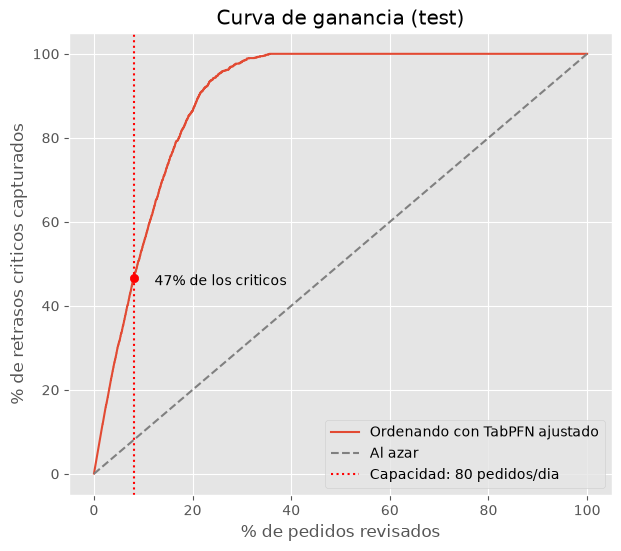

In [41]:
# Curva de ganancia: % de criticos capturados al revisar el x% de los pedidos (ordenados por el modelo)
pct_revisado=np.arange(1, len(ranking)+1)/len(ranking)
pct_capturado=ranking["Es_critico"].cumsum().values/ranking["Es_critico"].sum()
captura_en_capacidad=pct_capturado[k-1]
plt.figure(figsize=(7,6))
plt.plot(pct_revisado*100, pct_capturado*100, label=f"Ordenando con {mejor_nombre}")
plt.plot([0,100], [0,100], "--", color="gray", label="Al azar")
plt.axvline(capacidad_pct*100, color="red", linestyle=":", label=f"Capacidad: {capacidad_dia} pedidos/dia")
plt.scatter([capacidad_pct*100], [captura_en_capacidad*100], color="red", zorder=3)
plt.annotate(f"{captura_en_capacidad:.0%} de los criticos", (capacidad_pct*100, captura_en_capacidad*100),
             xytext=(15, -5), textcoords="offset points")
plt.xlabel("% de pedidos revisados")
plt.ylabel("% de retrasos criticos capturados")
plt.title("Curva de ganancia (test)")
plt.legend(loc="lower right")
plt.show()

### Beneficio del modelo

La capacidad es **diaria**: cada día el coordinador revisa los 80 pedidos más riesgosos **de ese día**. Por eso el plan se mide con un ranking día a día: en cada fecha del test se revisa el 8 % de los pedidos de esa fecha. El ranking global (todo el test junto, como en la curva de ganancia) da una cifra más alta, pero supone que se pueden revisar más pedidos los días malos.

In [42]:
# Ranking dia a dia: en cada fecha se revisa el 8% de los pedidos de esa fecha (la capacidad es diaria)
revisados_dia, capturados_dia=0, 0
for fecha, grupo in plan.groupby("Fecha"):
    k_dia=int(round(capacidad_pct*len(grupo)))
    revisados_dia+=k_dia
    capturados_dia+=grupo.nlargest(k_dia, "Prob_critico")["Es_critico"].sum()
capturados_global=ranking["Es_critico"].head(k).sum()
capturados_azar=revisados_dia*plan["Es_critico"].mean()   # valor esperado al revisar la misma cantidad al azar
lift=capturados_dia/capturados_azar
beneficio=pd.DataFrame({"Revisados": [revisados_dia, k, revisados_dia],
                        "Criticos capturados": [capturados_dia, capturados_global, capturados_azar]},
                       index=["Modelo, ranking diario (el plan)", "Modelo, ranking global (curva)", "Al azar"])
beneficio["Precision"]=beneficio["Criticos capturados"]/beneficio["Revisados"]
beneficio["% de criticos capturados"]=beneficio["Criticos capturados"]/plan["Es_critico"].sum()
beneficio["Criticos capturados por dia (escala real)"]=beneficio["Criticos capturados"]/dias_test
print(f"Lift = {capturados_dia} / {capturados_azar:.1f} = {lift:.2f}")
beneficio.round(3)

Lift = 456 / 103.2 = 4.42


,Revisados,Criticos capturados,Precision,% de criticos capturados,Criticos capturados por dia (escala real)
"Modelo, ranking diario (el plan)",704,456.00,0.648,0.356,51.817
"Modelo, ranking global (curva)",704,597.00,0.848,0.466,67.839
Al azar,704,103.17,0.147,0.080,11.724


### Retorno de la inversión (ROI)

Evaluación anual en pesos chilenos. Cada cifra tiene una fuente o está marcada como **supuesto**.

| Concepto | Valor | Fuente o supuesto |
|---|---:|---|
| Pedidos diarios | ~1.000 | Promedio diario del dataset; **supuesto**: la operación chilena tiene el mismo volumen |
| Días de operación al año | 365 | Los datos tienen entregas los 7 días de la semana |
| Costo del coordinador | $1.500.000 al mes | Avisos de 2026 para coordinador de despacho en Santiago: $780.000 a $1.350.000 líquidos (Chiletrabajos, Computrabajo). Se suma el costo empresa (cotizaciones y seguros) |
| Costo variable de cada acción | $1.500 | **Supuesto**: bono al repartidor reasignado o aviso al cliente |
| Ticket promedio | $85.000 | CCS: $83.000 en el CyberMonday 2026 y ~$93.000 en el CyberDay 2026 |
| Margen bruto | 25 % | **Supuesto** |
| Compras al año por cliente | 4 | **Supuesto** |
| Probabilidad de perder al cliente tras un retraso crítico | 15 % | **Supuesto conservador**: el 48 % dice dejar de comprar tras una mala experiencia (Logisfashion Chile, 2026) |
| Despacho devuelto como compensación | $4.000 | Envíos en Chile de $3.000 a $15.000 (Tiendanube; Correos de Chile $3.000 a $8.000) |
| Atención del reclamo | $3.000 | **Supuesto**: unos 10 minutos de un ejecutivo de servicio al cliente |
| Efectividad de la acción | 40 % | **Supuesto**: de los críticos revisados a tiempo, 4 de cada 10 dejan de serlo |
| Desarrollo del modelo | 80 h × $15.000 | Sueldo de data scientist en Chile: $1,4 a $2,5 millones al mes (Chiletrabajos, Indeed, 2026) |
| Mantención | 8 h al mes de reentrenamiento + $150.000 al mes de servidor con GPU | **Supuesto** |

- **Costo de un retraso crítico** = despacho devuelto + atención del reclamo + probabilidad de fuga × margen anual del cliente.
- **Beneficio** = críticos capturados al año × efectividad × costo de un retraso crítico.
- **Costo** = coordinador + acciones realizadas (incluidas las falsas alarmas) + modelo (solo si se usa el modelo).
- **ROI** = (Beneficio − Costo) / Costo.

In [43]:
# Supuestos economicos (pesos chilenos)
dias_anio=365
costo_coordinador_anual=1_500_000*12
costo_accion=1_500
ticket, margen, compras_anio, prob_fuga=85_000, 0.25, 4, 0.15
costo_despacho, costo_reclamo=4_000, 3_000
efectividad=0.40
costo_critico=costo_despacho + costo_reclamo + prob_fuga*ticket*margen*compras_anio
costo_modelo_anual=80*15_000 + 12*8*15_000 + 12*150_000   # desarrollo + reentrenamiento + servidor
print(f"Costo de un retraso critico: ${costo_critico:,.0f}")
print(f"Costo anual del modelo: ${costo_modelo_anual:,.0f}")

# ROI anual de revisar capacidad_dia pedidos al dia
def calcular_roi(criticos_dia, con_modelo, costo_critico=costo_critico, efectividad=efectividad, costo_accion=costo_accion):
    beneficio=criticos_dia*dias_anio*efectividad*costo_critico
    costo=costo_coordinador_anual + capacidad_dia*dias_anio*costo_accion + (costo_modelo_anual if con_modelo else 0)
    return beneficio, costo, (beneficio-costo)/costo

criticos_dia={"Con el modelo": capturados_dia/dias_test, "Al azar": capturados_azar/dias_test}
filas=[]
for nombre, cd in criticos_dia.items():
    b, c, r=calcular_roi(cd, con_modelo=(nombre=="Con el modelo"))
    filas.append({"Estrategia": nombre, "Criticos capturados al anio": cd*dias_anio, "Beneficio": b, "Costo": c,
                  "Beneficio neto": b-c, "ROI": r})
roi=pd.DataFrame(filas).set_index("Estrategia")
roi.round(2)

Costo de un retraso critico: $19,750
Costo anual del modelo: $4,440,000


,Criticos capturados al anio,Beneficio,Costo,Beneficio neto,ROI
Estrategia,,,,,
Con el modelo,18913.2,1.494143e+08,66240000,83174311.23,1.26
Al azar,4279.1,3.380487e+07,61800000,-27995130.44,-0.45


### Sensibilidad

¿Qué pasa si los supuestos más inciertos suben o bajan? Variamos el costo de un retraso crítico y la efectividad de la acción entre la mitad y 1,5 veces su valor.

,Con el modelo: costo critico,Con el modelo: efectividad,Con el modelo: costo accion,Al azar: costo critico,Al azar: efectividad,Al azar: costo accion
Factor sobre el supuesto,,,,,,
50%,0.13,0.13,2.37,-0.73,-0.73,-0.15
75%,0.69,0.69,1.70,-0.59,-0.59,-0.34
100%,1.26,1.26,1.26,-0.45,-0.45,-0.45
125%,1.82,1.82,0.94,-0.32,-0.32,-0.54
150%,2.38,2.38,0.70,-0.18,-0.18,-0.60


Con el modelo: ROI = 0 si un retraso critico cuesta $8,756
Al azar: ROI = 0 si un retraso critico cuesta $36,106


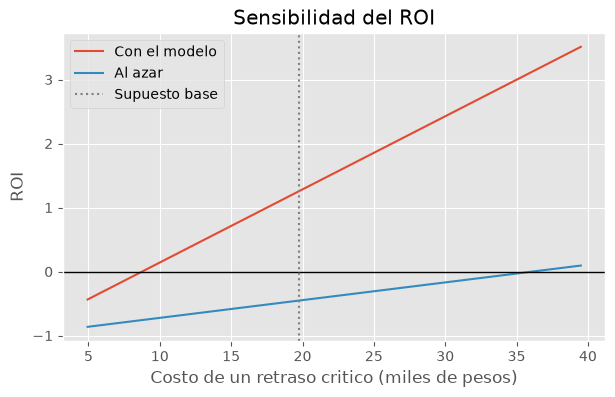

In [44]:
# Sensibilidad del ROI a los dos supuestos mas inciertos
factores=[0.5, 0.75, 1.0, 1.25, 1.5]
sens=pd.DataFrame(index=[f"{f:.0%}" for f in factores])
sens.index.name="Factor sobre el supuesto"
for nombre, cd in criticos_dia.items():
    sens[f"{nombre}: costo critico"]=[calcular_roi(cd, nombre=="Con el modelo", costo_critico=costo_critico*f)[2] for f in factores]
    sens[f"{nombre}: efectividad"]=[calcular_roi(cd, nombre=="Con el modelo", efectividad=min(efectividad*f, 1))[2] for f in factores]
    sens[f"{nombre}: costo accion"]=[calcular_roi(cd, nombre=="Con el modelo", costo_accion=costo_accion*f)[2] for f in factores]
display(sens.round(2))

# Punto de equilibrio: costo de un critico con el que el ROI es 0
for nombre, cd in criticos_dia.items():
    b, c, r=calcular_roi(cd, nombre=="Con el modelo")
    print(f"{nombre}: ROI = 0 si un retraso critico cuesta ${costo_critico*c/b:,.0f}")

# Grafico: ROI segun el costo de un retraso critico
costos=np.linspace(0.25, 2, 50)*costo_critico
plt.figure(figsize=(7,4))
for nombre, cd in criticos_dia.items():
    plt.plot(costos/1000, [calcular_roi(cd, nombre=="Con el modelo", costo_critico=c)[2] for c in costos], label=nombre)
plt.axhline(0, color="black", linewidth=1)
plt.axvline(costo_critico/1000, color="gray", linestyle=":", label="Supuesto base")
plt.xlabel("Costo de un retraso critico (miles de pesos)")
plt.ylabel("ROI")
plt.title("Sensibilidad del ROI")
plt.legend()
plt.show()

In [45]:
# Guardar el plan para el simulador y la presentacion
ranking[["Prioridad", "Order_ID", "Fecha", "Prob_critico", "Clase_predicha", "Clase_real", "Es_critico",
         "Agent_Rating", "Traffic", "distancia_km", "Accion"]].round(4).to_csv("resultados/plan_ranking_test.csv", index=False)
roi.round(2).to_csv("resultados/plan_roi.csv")
sens.round(3).to_csv("resultados/plan_sensibilidad.csv")
pd.Series({"mejor_modelo": mejor_nombre, "pedidos_dia": pedidos_dia, "capacidad_dia": capacidad_dia,
           "capacidad_pct": capacidad_pct, "k": k, "dias_test": dias_test,
           "revisados_dia_test": revisados_dia, "capturados_modelo": capturados_dia, "capturados_global": capturados_global,
           "capturados_azar": capturados_azar, "lift": lift, "criticos_test": plan["Es_critico"].sum(),
           "costo_critico": costo_critico, "costo_modelo_anual": costo_modelo_anual,
           "costo_coordinador_anual": costo_coordinador_anual, "costo_accion": costo_accion,
           "efectividad": efectividad, "dias_anio": dias_anio}).to_json("resultados/plan_resumen.json", indent=1)
print("Plan guardado en resultados/")

Plan guardado en resultados/


---
# Parte F. Ventana de operación (simulador what-if)

**Pregunta de negocio:** ¿en qué rangos deben operar las variables para evitar el retraso crítico?

**Método (dependencia parcial):** tomamos 200 pedidos reales de test, les cambiamos **una variable a la vez** a cada valor de una grilla, dejando todo lo demás igual, y promediamos la probabilidad de retraso crítico que entrega el mejor modelo. Así vemos cómo cambia el riesgo con cada variable. Es lo mismo que hace el simulador con un pedido, pero promediado sobre muchos pedidos.

- **Variables que la empresa controla:** distancia (radio de cobertura o tienda asignada), calificación del repartidor (a quién se asigna), vehículo y tiempo de espera hasta el retiro.
- **Contexto que no controla:** tráfico, clima, hora, zona, edad del repartidor y categoría del producto. Sirven para decidir **cuándo** ser más estricto.

**Cuidado:** el modelo muestra asociaciones, no causas. Una ventana basada en el modelo hay que validarla con una prueba piloto.

In [46]:
# Muestra de 200 pedidos de test, ya con las variables calculadas (paso 1 del pipeline)
muestra=variables.transform(X_test).sample(200, random_state=semilla)
meta=(y_train==clase_critica).mean()   # tasa de criticos en train: la referencia
grilla={"distancia_km": np.arange(1, 22, 1),
        "Agent_Rating": np.round(np.arange(3.0, 5.01, 0.1), 1),
        "espera_retiro_min": [5, 10, 15],
        "hora_pedido": [0, 8, 10, 12, 14, 16, 17, 18, 19, 20, 21, 22, 23],
        "Agent_Age": np.arange(15, 51, 5),
        "Vehicle": ["motorcycle", "scooter", "van"],
        "Traffic": ["Low", "Medium", "High", "Jam"],
        "Weather": ["Sunny", "Cloudy", "Fog", "Windy", "Stormy", "Sandstorms"],
        "Area": ["Urban", "Metropolitian", "Semi-Urban", "Other"]}
# Una copia de la muestra por cada valor de la grilla
escenarios=[]
for col, valores in grilla.items():
    for v in valores:
        esc=muestra.copy()
        esc[col]=v
        esc["variable"], esc["valor"]=col, str(v)
        escenarios.append(esc)
# Grilla doble: distancia x trafico (el radio de cobertura depende de la congestion)
for t in grilla["Traffic"]:
    for d in grilla["distancia_km"]:
        esc=muestra.copy()
        esc["Traffic"], esc["distancia_km"]=t, d
        esc["variable"], esc["valor"]="distancia_x_trafico", f"{t}|{d}"
        escenarios.append(esc)
escenarios=pd.concat(escenarios, ignore_index=True)
print("Filas a predecir:", len(escenarios))

Filas a predecir: 33400


In [47]:
# Una sola prediccion para todos los escenarios (pasos 2 y 3 del pipeline: preprocesado y modelo)
mejor_modelo={"MLP base": nn, "MLP ajustada": nn_best, "TabPFN base": pfn, "TabPFN ajustado": pfn_best}[mejor_nombre]
inicio=time()
escenarios["Prob_critico"]=mejor_modelo[1:].predict_proba(escenarios.drop(columns=["variable", "valor"]))[:, clase_critica]
print("Tiempo (s):", round(time()-inicio, 1))
dependencia=escenarios.groupby(["variable", "valor"], sort=False)["Prob_critico"].mean().reset_index()
print(f"Probabilidad media de critico en la muestra original: {mejor_modelo[1:].predict_proba(muestra)[:, clase_critica].mean():.3f}")

Tiempo (s): 130.3


Probabilidad media de critico en la muestra original: 0.159


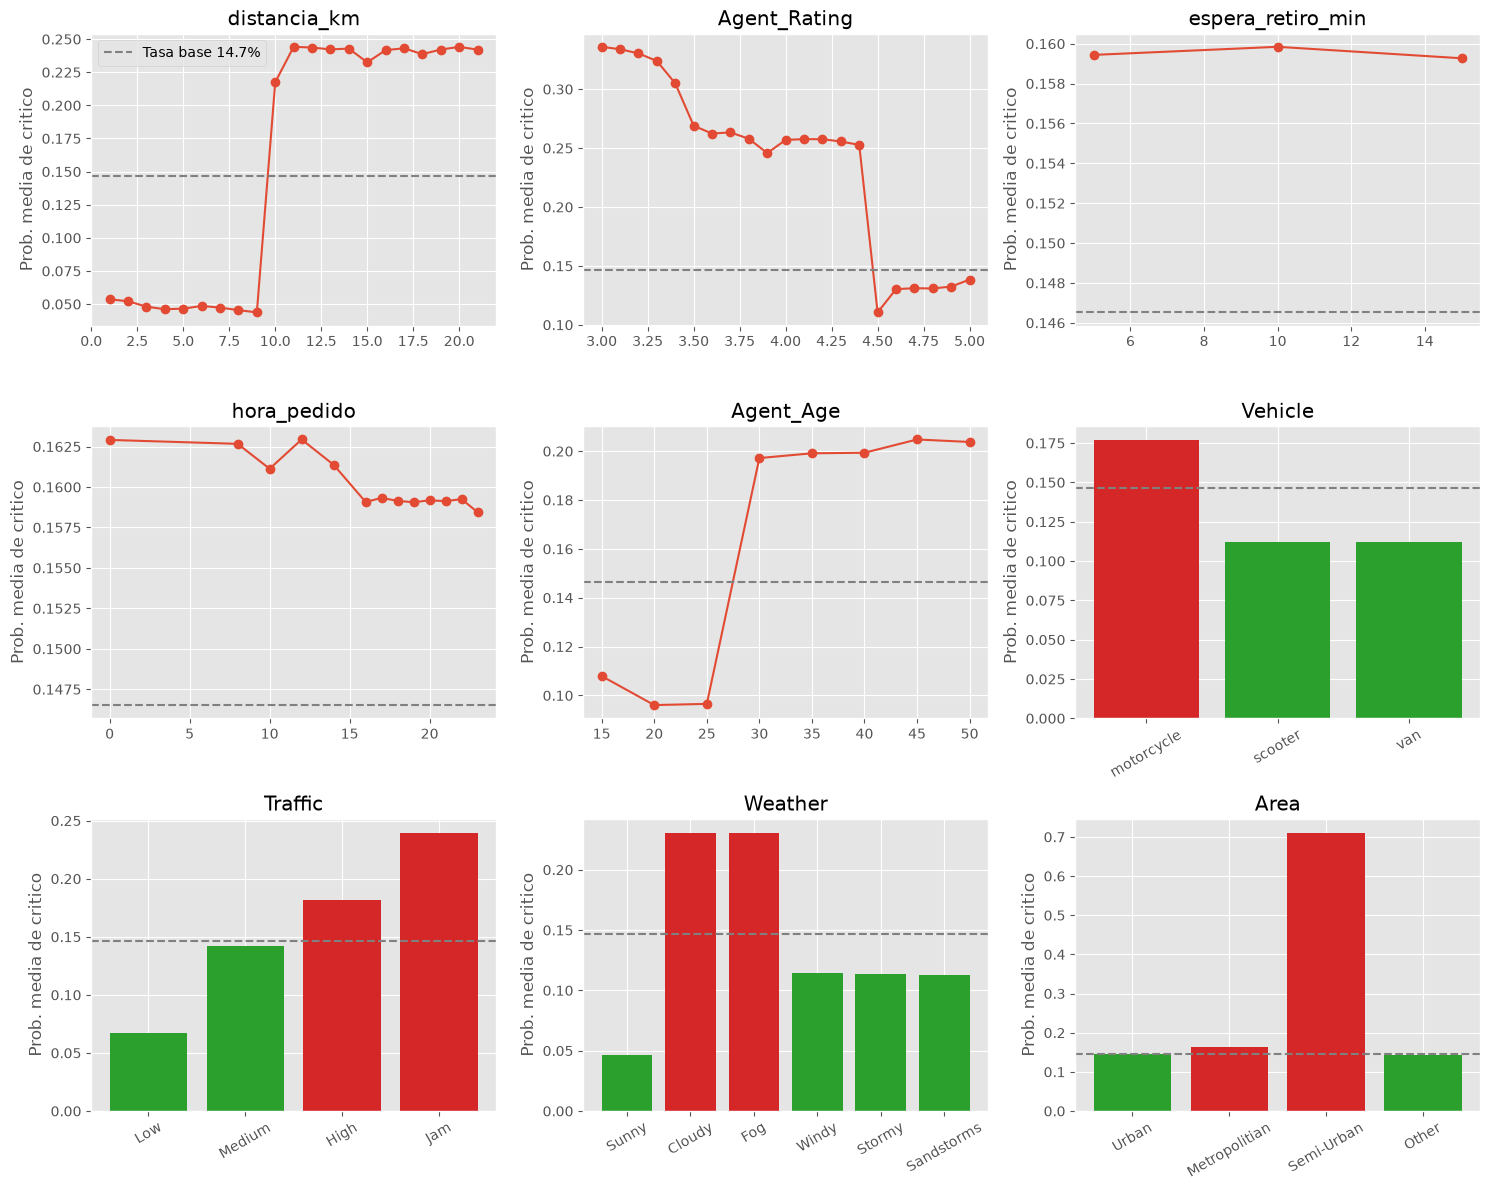

In [48]:
# Graficos: probabilidad media de retraso critico segun cada variable
fig, ax=plt.subplots(3, 3, figsize=(15,12))
for eje, col in zip(ax.ravel(), grilla):
    d=dependencia[dependencia["variable"]==col]
    if col in ["Vehicle", "Traffic", "Weather", "Area"]:
        eje.bar(d["valor"], d["Prob_critico"], color=["tab:green" if p<meta else "tab:red" for p in d["Prob_critico"]])
        eje.tick_params(axis="x", rotation=30)
    else:
        eje.plot(d["valor"].astype(float), d["Prob_critico"], marker="o")
    eje.axhline(meta, color="gray", linestyle="--", label=f"Tasa base {meta:.1%}")
    eje.set_title(col)
    eje.set_ylabel("Prob. media de critico")
ax[0,0].legend()
plt.tight_layout()
plt.show()

In [49]:
# Ventana de operacion: valores de cada variable con riesgo bajo la tasa base
ventana=[]
for col in grilla:
    d=dependencia[dependencia["variable"]==col]
    ok=d[d["Prob_critico"]<meta]["valor"].tolist()
    if col in ["Vehicle", "Traffic", "Weather", "Area"]:
        rango=", ".join(ok) if ok else "ninguno"
    else:
        rango=f"{min(map(float, ok)):g} a {max(map(float, ok)):g}" if ok else "ninguno"
    ventana.append({"Variable": col, "Valores con riesgo bajo la tasa base": rango,
                    "Prob. minima": d["Prob_critico"].min(), "Prob. maxima": d["Prob_critico"].max(),
                    "Rango de efecto": d["Prob_critico"].max()-d["Prob_critico"].min()})
ventana=pd.DataFrame(ventana).sort_values("Rango de efecto", ascending=False)
ventana.round(3)

,Variable,Valores con riesgo bajo la tasa base,Prob. minima,Prob. maxima,Rango de efecto
8,Area,"Urban, Other",0.144,0.711,0.567
1,Agent_Rating,4.5 a 5,0.111,0.336,0.225
0,distancia_km,1 a 9,0.044,0.244,0.200
7,Weather,"Sunny, Windy, Stormy, Sandstorms",0.046,0.231,0.184
6,Traffic,"Low, Medium",0.067,0.240,0.172
4,Agent_Age,15 a 25,0.096,0.205,0.109
5,Vehicle,"scooter, van",0.112,0.177,0.065
3,hora_pedido,ninguno,0.158,0.163,0.005
2,espera_retiro_min,ninguno,0.159,0.160,0.001


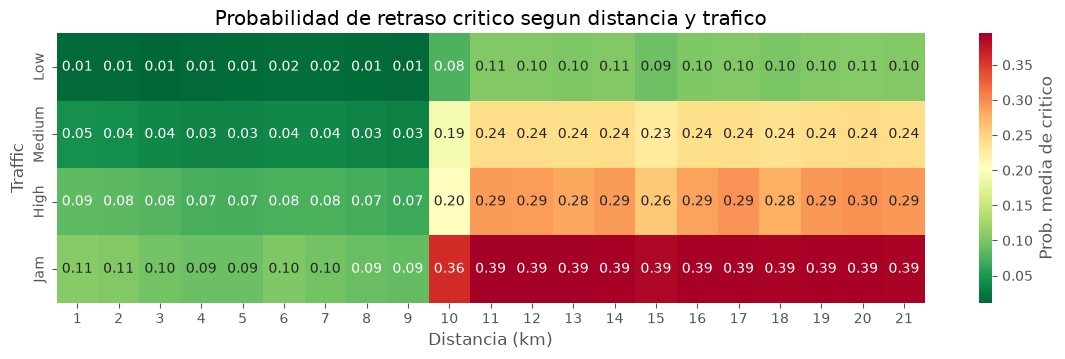

Distancia maxima (km) con riesgo bajo la tasa base, por nivel de trafico:
Traffic
Low       21
Medium     9
High       9
Jam        9


In [50]:
# Radio de cobertura segun el trafico: distancia maxima con riesgo bajo la tasa base
doble=dependencia[dependencia["variable"]=="distancia_x_trafico"].copy()
doble[["Traffic", "distancia_km"]]=doble["valor"].str.split("|", expand=True)
doble["distancia_km"]=doble["distancia_km"].astype(int)
tabla_doble=doble.pivot(index="Traffic", columns="distancia_km", values="Prob_critico").loc[grilla["Traffic"]]
plt.figure(figsize=(14,3.5))
sns.heatmap(tabla_doble, cmap="RdYlGn_r", annot=True, fmt=".2f", cbar_kws={"label": "Prob. media de critico"})
plt.title("Probabilidad de retraso critico segun distancia y trafico")
plt.xlabel("Distancia (km)")
plt.show()
radio=(tabla_doble<meta).apply(lambda fila: fila[fila].index.max() if fila.any() else 0, axis=1)
print("Distancia maxima (km) con riesgo bajo la tasa base, por nivel de trafico:")
print(radio.to_string())

In [51]:
# Efecto de operar dentro de la ventana: aplicar las palancas que la empresa controla a los 200 pedidos
dentro=muestra.copy()
dentro["Agent_Rating"]=dentro["Agent_Rating"].clip(lower=4.5)                       # asignar repartidores con nota >= 4,5
dentro["distancia_km"]=[min(d, radio[t]) if t in radio.index and radio[t]>0 else d    # respetar el radio segun trafico
                        for d, t in zip(dentro["distancia_km"], dentro["Traffic"])]                # (sin trafico: se deja igual)
p_antes=mejor_modelo[1:].predict_proba(muestra)[:, clase_critica]
p_despues=mejor_modelo[1:].predict_proba(dentro)[:, clase_critica]
print(f"Prob. media de critico: {p_antes.mean():.3f} -> {p_despues.mean():.3f}")
print(f"Pedidos con prob. de critico > 50%: {(p_antes>0.5).sum()} -> {(p_despues>0.5).sum()} de {len(muestra)}")

Prob. media de critico: 0.159 -> 0.030
Pedidos con prob. de critico > 50%: 32 -> 4 de 200


In [52]:
# Guardar la ventana de operacion para el simulador y la presentacion
dependencia.round(4).to_csv("resultados/ventana_dependencia.csv", index=False)
ventana.round(4).to_csv("resultados/ventana_operacion.csv", index=False)
tabla_doble.round(4).to_csv("resultados/ventana_distancia_trafico.csv")
pd.Series({"meta": meta, "radio_km": radio.to_dict(), "p_antes": p_antes.mean(), "p_despues": p_despues.mean(),
           "altos_antes": int((p_antes>0.5).sum()), "altos_despues": int((p_despues>0.5).sum()),
           "n_muestra": len(muestra)}).to_json("resultados/ventana_resumen.json", indent=1)
print("Ventana guardada en resultados/")

Ventana guardada en resultados/


---
# Parte G. Conclusiones del Hito 2

Todas las cifras salen de las partes E y F y de `resultados/plan_*` y `resultados/ventana_*`.

| Pregunta | Respuesta |
|---|---|
| **¿Qué clase se prioriza?** | **Retraso crítico** (más de 3 horas): 1.282 de 8.748 pedidos de test (14,7 %). Es el retraso que genera devolución del despacho, reclamos y clientes perdidos. |
| **¿Cuánto rinde el modelo con la misma capacidad?** | Con 80 revisiones al día (8 % de los pedidos), revisando cada día los pedidos más riesgosos de ese día, se detectan **456 críticos** en test contra **103 al azar**: **lift = 4,4**. En escala real son ~52 críticos al día contra ~12, con una precisión de 64,8 % contra 14,7 %. Ordenando todo el test junto (curva de ganancia) se captura el 47 % de los críticos; usamos la cifra diaria, que respeta la capacidad. |
| **¿Conviene económicamente?** | Con un costo de $19.750 por retraso crítico y 40 % de efectividad de la acción, el **ROI anual es 1,26 con el modelo** (beneficio neto ≈ $83 M) y **−0,45 al azar**. Con el modelo, el plan sigue siendo rentable aunque el costo de un crítico o la efectividad bajen a la mitad (ROI 0,13). El punto de equilibrio es $8.756 por crítico. |
| **¿Cuál es la ventana de operación?** | Asignar repartidores con **nota ≥ 4,5** y despachar **hasta 9 km** cuando el tráfico es medio, alto o atasco (sin límite con tráfico bajo). Aplicadas a 200 pedidos reales, estas dos reglas bajan la probabilidad media de retraso crítico de **15,9 % a 3,0 %**, y los pedidos con más de 50 % de riesgo de 32 a 4. El clima nublado o con niebla y la zona semiurbana son los contextos más riesgosos. La hora y la espera hasta el retiro casi no cambian el riesgo cuando lo demás está fijo. |
| **¿Qué limita el plan?** | Con 80 revisiones al día solo se alcanza el 36 % de los críticos: es un límite de capacidad. El recall del modelo para la clase crítica es 0,765. Cerca de 35 % de las revisiones son falsas alarmas, casi todas retrasos moderados. La ventana muestra asociaciones, no causas: hay que validarla con un piloto. Los datos son de la India (2022) y los costos son supuestos chilenos; antes de usarlo hay que reentrenar con datos propios y revisar el F1 macro cada mes. |

**Recomendación:** usar **TabPFN ajustado** para ordenar cada día los pedidos por probabilidad de retraso crítico. Un coordinador revisa los 80 primeros, y la operación se ajusta a la ventana recomendada. Primer paso: un piloto de un mes en una zona, midiendo críticos detectados, falsas alarmas y reclamos. El simulador (`simulador/`) usa este mismo modelo con `predict_proba` para probar escenarios en vivo.


## Declaración de uso de inteligencia artificial

Se utilizó asistencia de IA (Claude) para revisar la estructura del notebook, depurar código, construir el simulador y redactar la documentación de las decisiones. Las fuentes de los costos del ROI se buscaron con ayuda de IA y están citadas en la parte E; los demás costos son supuestos declarados. El grupo eligió el dataset, definió los cortes de la variable objetivo, verificó los resultados y debe ser capaz de explicar cada paso del pipeline, la MLP, TabPFN, el F1 macro y la comparación final durante la revisión oral.